# Exercise 15: K-means Clustering - Solution
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

## Task 1: Load the Iris dataset.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

iris = load_iris(as_frame=True)
X = iris.data        # 150 x 4
y = iris.target      # 0, 1, 2  — used ONLY for interpretation
feature_names = iris.feature_names
class_names   = list(iris.target_names)

print('Shape of X:', X.shape)
print('Classes   :', class_names)

Shape of X: (150, 4)
Classes   : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## Task 2: Standardize the features.

In [ ]:
scaler = StandardScaler()
X_std  = scaler.fit_transform(X)

print('Mean per feature:', X_std.mean(axis=0).round(3))
print('Std per feature :', X_std.std(axis=0).round(3))

Mean per feature: [-0. -0. -0. -0.]
Std per feature : [1. 1. 1. 1.]


## Task 3: Sweep K and record distortion + silhouette score.

In [ ]:
K_values = list(range(2, 9))
rows = []
for K in K_values:
    km = KMeans(
        n_clusters=K,
        init='k-means++',
        n_init=10,
        random_state=2026
    ).fit(X_std)
    sil = silhouette_score(X_std, km.labels_)
    rows.append({
        'K'           : K,
        'Distortion J': round(km.inertia_, 4),
        'Silhouette'  : round(sil,         4),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

 K  Distortion J  Silhouette
 2      222.3617      0.5818
 3      139.8205      0.4599
 4      114.0925      0.3869
 5       90.8074      0.3427
 6       79.9989      0.3266
 7       71.0334      0.3277
 8       64.0045      0.3045


## Task 4: Plot the elbow curve and the silhouette curve.

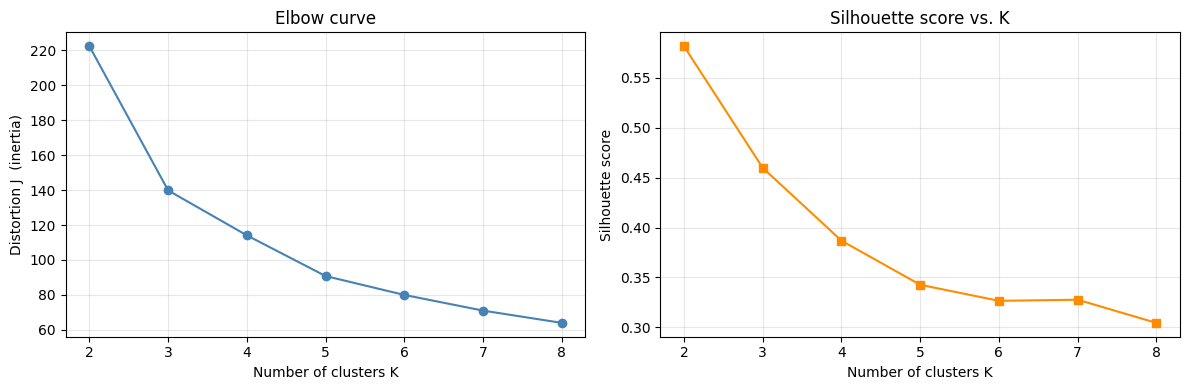

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(results['K'], results['Distortion J'], 'o-', color='steelblue')
axes[0].set_xlabel('Number of clusters K')
axes[0].set_ylabel('Distortion J  (inertia)')
axes[0].set_title('Elbow curve')
axes[0].grid(alpha=0.3)

axes[1].plot(results['K'], results['Silhouette'], 's-', color='darkorange')
axes[1].set_xlabel('Number of clusters K')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score vs. K')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Task 5: Choose the best K by silhouette.

In [ ]:
best_idx = results['Silhouette'].idxmax()
best_K   = int(results.loc[best_idx, 'K'])
best_sil = float(results.loc[best_idx, 'Silhouette'])

print(f'Best K (silhouette-based) : {best_K}')
print(f'Best silhouette score     : {best_sil:.4f}')

Best K (silhouette-based) : 2
Best silhouette score     : 0.5818


## Task 6: Fit K-means with `best_K` and report distortion + cluster sizes.

In [ ]:
kmeans = KMeans(
    n_clusters=best_K,
    init='k-means++',
    n_init=10,
    random_state=2026
).fit(X_std)

labels  = kmeans.labels_
centers = kmeans.cluster_centers_
J       = kmeans.inertia_

print(f'Final distortion J : {J:.4f}')
print('Cluster sizes      :')
print(pd.Series(labels).value_counts().sort_index())

Final distortion J : 222.3617
Cluster sizes      :
0     50
1    100
Name: count, dtype: int64


## Task 7: Visualize the clusters in 2D PCA space.

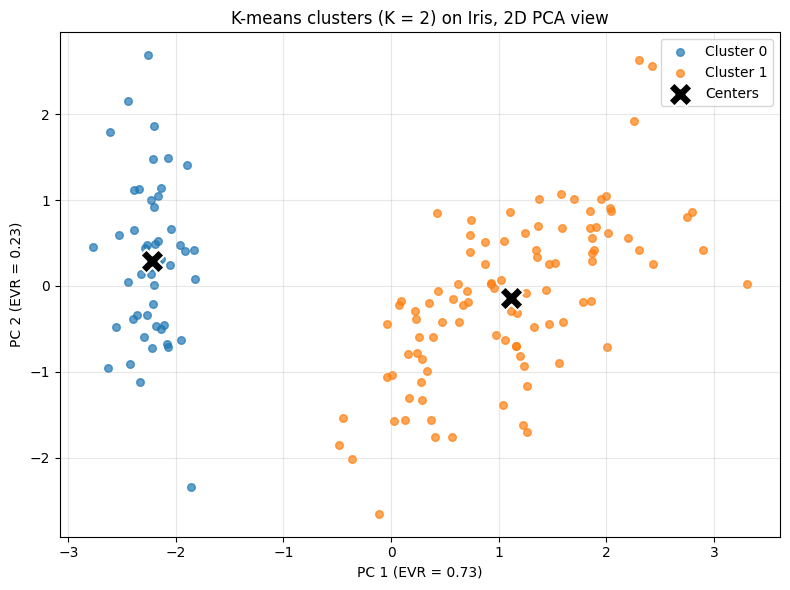

In [ ]:
pca = PCA(n_components=2)
X_2d       = pca.fit_transform(X_std)
centers_2d = pca.transform(centers)

plt.figure(figsize=(8, 6))
for k in range(best_K):
    pts = X_2d[labels == k]
    plt.scatter(pts[:, 0], pts[:, 1], label=f'Cluster {k}', alpha=0.7, s=30)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1],
            marker='X', s=300, c='black', edgecolors='white',
            linewidth=1.5, label='Centers')
plt.xlabel(f'PC 1 (EVR = {pca.explained_variance_ratio_[0]:.2f})')
plt.ylabel(f'PC 2 (EVR = {pca.explained_variance_ratio_[1]:.2f})')
plt.title(f'K-means clusters (K = {best_K}) on Iris, 2D PCA view')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()